In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/cookie_cats.csv")
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
print(df.dtypes)
print(df.isnull().sum())
print(df["version"].value_counts())
print(df[["retention_1", "retention_7"]].mean().round(4))

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
retention_1    0.4452
retention_7    0.1861
dtype: float64


# Cookie Cats A/B Test: does moving the gate from level 30 to 40 hurt retention?

**Decision:** ship the gate at level 40, or keep it at level 30.

**Primary metric:** 7-day retention (share of players who return 7 days after install).
**Secondary metric:** 1-day retention.
**Supporting metric:** game rounds played in the first 14 days.

**Hypotheses (7-day retention)**
- H0: retention is the same in gate_30 and gate_40.
- H1: retention differs between gate_30 and gate_40 (two-sided).

**Why 7-day retention is primary:** it reflects whether players stay engaged beyond the first session, which matters more for the business than a 1-day return.

In [3]:
from scipy import stats

counts = df["version"].value_counts()
print(counts)

chi2, p = stats.chisquare(counts)   # null hypothesis: players are split 50/50
print(round(chi2, 2), round(p, 4))

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
6.9 0.0086


In [4]:
print("duplicate user IDs:", df["userid"].duplicated().sum())

duplicate user IDs: 0


count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64
players with 0 rounds: 3994
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True


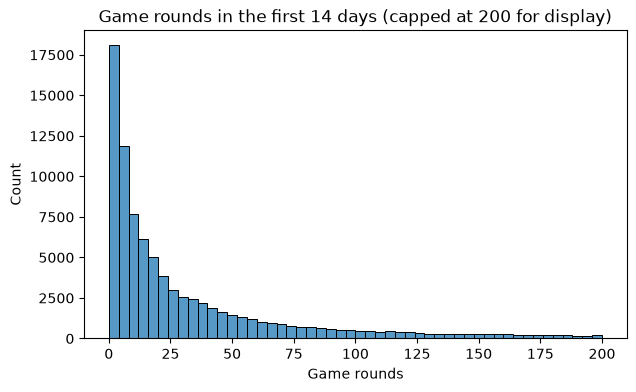

In [5]:
print(df["sum_gamerounds"].describe())
print("players with 0 rounds:", (df["sum_gamerounds"] == 0).sum())
print(df.sort_values("sum_gamerounds", ascending=False).head(5))

plt.figure(figsize=(7, 4))
sns.histplot(df[df["sum_gamerounds"] <= 200]["sum_gamerounds"], bins=50)
plt.title("Game rounds in the first 14 days (capped at 200 for display)")
plt.xlabel("Game rounds")
plt.show()

In [6]:
summary = df.groupby("version").agg(
    players=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
    median_rounds=("sum_gamerounds", "median"),
    mean_rounds=("sum_gamerounds", "mean"),
)
print(summary.round(4))

         players  retention_1  retention_7  median_rounds  mean_rounds
version                                                               
gate_30    44700       0.4482       0.1902           17.0      52.4563
gate_40    45489       0.4423       0.1820           16.0      51.2988


## Data checks before testing

- **Missing values / duplicates:** none, and 0 duplicate user IDs, so the groups are independent.
- **Sample ratio:** 45,489 players in gate_40 vs 44,700 in gate_30. Chi-square test against a 50/50 split gives p = 0.0086. That is below 0.05 but above the stricter 0.001 threshold commonly used for sample-ratio alerts, so I continue with the analysis but record it as a limitation and would ask engineering to confirm the randomisation.
- **Game rounds are very skewed:** median 16 vs mean 51.9. One gate_30 player has 49,854 rounds (about 3,500 per day), which is almost certainly a bot or a logging error. Without that player, gate_30's mean falls from 52.46 to about 51.34, level with gate_40 (51.30). Retention is yes/no per player, so this row barely affects it and I keep it there. For any comparison of rounds I use the median or exclude it.
- **Players with 0 rounds:** 3,994 (4.4%), split across groups as [fill in after running the command].
- **Descriptive only (not yet tested):** 7-day retention is 19.02% in gate_30 vs 18.20% in gate_40.

In [7]:
from scipy.stats import norm

g30 = df[df["version"] == "gate_30"]
g40 = df[df["version"] == "gate_40"]

x1, n1 = g30["retention_7"].sum(), len(g30)
x2, n2 = g40["retention_7"].sum(), len(g40)
p1, p2 = x1 / n1, x2 / n2

p_pool = (x1 + x2) / (n1 + n2)                      # pooled rate under H0
se = np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))   # standard error of the difference
z = (p1 - p2) / se
p_value = 2 * (1 - norm.cdf(abs(z)))                  # two-sided

print(round(p1, 4), round(p2, 4), round(p1 - p2, 4))
print("z =", round(z, 3), " p =", round(p_value, 4))

0.1902 0.182 0.0082
z = 3.164  p = 0.0016


In [8]:
from statsmodels.stats.proportion import proportions_ztest

def ztest(metric):
    counts = np.array([g30[metric].sum(), g40[metric].sum()])
    nobs = np.array([len(g30), len(g40)])
    return proportions_ztest(counts, nobs)

for m in ["retention_1", "retention_7"]:
    z, p = ztest(m)
    print(m, " z =", round(z, 3), " p =", round(p, 4))

retention_1  z = 1.784  p = 0.0744
retention_7  z = 3.164  p = 0.0016


## Test 1: two-proportion z-test

- **7-day retention (primary):** gate_30 19.02% vs gate_40 18.20%, a difference of 0.82 percentage points. z = 3.16, p = 0.0016 (two-sided). If there were no real difference between the versions, a gap this large would appear about 0.16% of the time, so I reject H0 at the 5% level.
- **1-day retention (secondary):** 44.82% vs 44.23%, z = 1.78, p = 0.0744. This does not reject H0 at 5%. The data cannot separate this gap from noise, which is not evidence that the versions are equal.
- I calculated the test by hand and with statsmodels (`proportions_ztest`), and both agree.
- Significance alone does not decide whether to ship. The size of the effect comes next.

In [9]:
# unpooled standard error (H0 no longer assumed), for a confidence interval
se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
diff = p1 - p2
lo, hi = diff - 1.96 * se_diff, diff + 1.96 * se_diff

print(f"difference (gate_30 - gate_40): {diff*100:.2f} percentage points")
print(f"95% CI: [{lo*100:.2f}, {hi*100:.2f}] percentage points")

difference (gate_30 - gate_40): 0.82 percentage points
95% CI: [0.31, 1.33] percentage points


In [10]:
relative_drop = (p1 - p2) / p1
print(f"relative drop in 7-day retention: {relative_drop*100:.1f}%")
print(f"per 100,000 installs, about {diff*100_000:.0f} fewer players are still active at day 7")

relative drop in 7-day retention: 4.3%
per 100,000 installs, about 820 fewer players are still active at day 7


## Effect size and confidence interval

- Difference in 7-day retention (gate_30 minus gate_40): 0.82 percentage points, 95% CI [0.31, 1.33].
- The interval excludes zero, consistent with the z-test (p = 0.0016). It shows the effect could plausibly be as small as 0.3 points or as large as 1.3 points.
- Relative drop in 7-day retention with gate_40: 4.3%. Per 100,000 installs, that is about 820 fewer players active at day 7 (plausible range about 310 to 1,330).
- Statistical significance is established. Whether the size matters commercially depends on the value of a retained player, which this dataset does not contain.
- If the team tolerated a drop of up to 0.3 points, the lower end of the interval (0.31) is only just above that tolerance, so the data does not support shipping on that criterion.

**bootstrap for the 7-day retention difference**

bootstrap 95% CI: [0.31, 1.34] percentage points


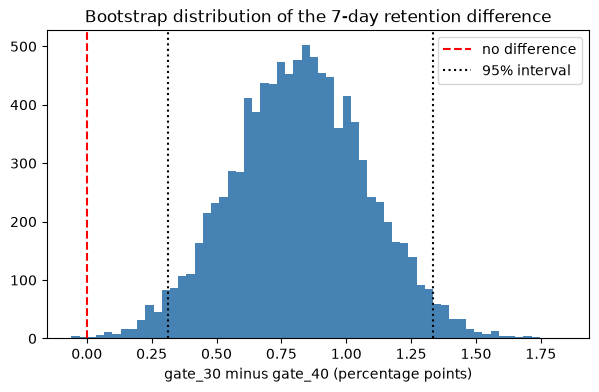

In [11]:
rng = np.random.default_rng(42)
B = 10_000

# Resampling a 0/1 column with replacement gives a count of 1s that follows
# Binomial(n, p_hat), so we draw the counts directly (same result, much faster).
boot_p1 = rng.binomial(n1, p1, B) / n1
boot_p2 = rng.binomial(n2, p2, B) / n2
boot_diff = (boot_p1 - boot_p2) * 100          # percentage points

lo_b, hi_b = np.percentile(boot_diff, [2.5, 97.5])
print(f"bootstrap 95% CI: [{lo_b:.2f}, {hi_b:.2f}] percentage points")

plt.figure(figsize=(7, 4))
plt.hist(boot_diff, bins=60, color="steelblue")
plt.axvline(0, color="red", linestyle="--", label="no difference")
plt.axvline(lo_b, color="black", linestyle=":")
plt.axvline(hi_b, color="black", linestyle=":", label="95% interval")
plt.title("Bootstrap distribution of the 7-day retention difference")
plt.xlabel("gate_30 minus gate_40 (percentage points)")
plt.legend()
plt.savefig("charts/bootstrap_retention7.png", dpi=150, bbox_inches="tight")
plt.show()

**bootstrap where it really helps (median game rounds)**

In [12]:
r30 = g30["sum_gamerounds"].to_numpy()
r40 = g40["sum_gamerounds"].to_numpy()
print("medians:", np.median(r30), np.median(r40))

B2 = 2000
diffs = np.empty(B2)
for i in range(B2):
    s30 = rng.choice(r30, size=len(r30), replace=True)
    s40 = rng.choice(r40, size=len(r40), replace=True)
    diffs[i] = np.median(s30) - np.median(s40)

print("bootstrap 95% CI for median difference:", np.percentile(diffs, [2.5, 97.5]))

medians: 17.0 16.0
bootstrap 95% CI for median difference: [0. 1.]
